# Eject! Notebook 1: The basic model (flat ground)

**Goal: find out how far volcanic blocks can land.**

This is **Notebook 1 of 2** in the ballistics modeling portion of CSAV 2026

Eject! is a calculator for **volcanic ballistic projectiles (VBPs)** — the large rocks thrown
from a volcano during an eruption. It finds the curved path (or the *trajectory*) of a block and
tells you **how far it can land from the vent**.

In this notebook, blocks land on **flat ground**. In the next notebook (Notebook 2 EJECT_withTopography), you will use the **real
shape** of a volcano and add the data to your hazard map in QGIS.

## To do:

- Learn the three inputs: **angle**, **speed**, and **block size**.
- Launch one block and look at its flight path.
- Test how the angle, the speed, and the size affect the landing distance.


## What is a volcanic ballistic projectile (VBP)?

The objects that Eject! models have a proper name: **volcanic ballistic projectiles (VBPs)**.

- A VBP is any **pyroclast** (a fragment ejected by an eruption) **larger than 6.4 cm**
  in length (think about the size of a tennis ball).
- There are two kinds: **blocks** (solid, cold rock) and **bombs** (still soft and *molten* when
  thrown).
- A VBP flies on its own curved path, like a thrown ball. Eject! draws that path (simplified).
- VBPs are a common hazard in **explosive** eruptions, and are most dangerous **within 5 km** of
  the vent (Taddeucci et al., 2017; Brown et al., 2017).


## How to use this notebook

- Run the cells **from top to bottom**. Click a cell, then press **Shift + Enter** OR click a cell and press the 'play' button.
- A cell often needs the result of an earlier cell, so DO NOT skip ahead.
- A **CHECK** note tells you what you should see when a step works.
- A **TIP** note gives advice about a common mistake.


## Words to know

A word bank is provided below. You can also refer to the word document.

| Word | Simple definition |
|------|----------------|
| **Vent** | The opening where the eruption comes out. The center of the map: point (0, 0). |
| **VBP** | *Volcanic ballistic projectile*, a thrown rock larger than 6.4 cm. Includes blocks and bombs. |
| **Block** | A *solid* (cold, hard) VBP. |
| **Bomb** | A *molten* (still soft and hot) VBP. |
| **Pyroclast** | Any piece of rock thrown out by an eruption. |
| **Ejection angle** | The launch angle above the ground, in degrees (°). Example: 45°. |
| **Initial velocity** | The launch speed, in meters per second (m/s). |
| **Diameter** | The width of the block, in meters (m). A bigger block is heavier. |
| **Trajectory** | The curved flight path of the block through the air. |
| **Impact point** | Where the block hits the ground. The landing spot. |
| **Hazard zone** | The area on a map that blocks can reach. The danger zone. |


## Please cite Eject! if you use it

- **Mastin, L.G. (2001).** *A simple calculator of ballistic trajectories for blocks ejected
  during volcanic eruptions.* U.S. Geological Survey Open-File Report 01-45, 16 p.
  https://pubs.usgs.gov/of/2001/0045/
- **Strehlow, K., Mastin, L.G., Sandri, L., Gottsmann, J.H., Kilgour, G., Rust, A.C., &
  Tonini, R. (2019).** *Eject! for Matlab.* https://vhub.org/resources/4543


## The choices you make

Eject! gives you three inputs (**angle, velocity, diameter**), but the model also makes other
choices for you behind the scenese. Before you trust a result, think about these other considerations (the same way
a lahar model needs a source and a volume):

1. **Launch energy**: how fast and at what angle blocks leave the vent. This is set by the
   eruption style (for example, phreatic vs. Vulcanian vs. Strombolian). *Velocity is the
   biggest and least certain control on how far blocks travel.*
2. **Block properties**: the size, the density, and the shape (drag) of the block. One block,
   or many sizes?
3. **Near-vent gas effect**: how large the reduced-drag zone is, where the eruption jet carries
   the block before normal air drag takes over. It is hidden in the model defaults, but it
   quietly controls the maximum distance.
4. **Environment**: the air (thinner air high up lets blocks travel farther), the wind, and the
   terrain (flat ground vs. the real slope).
5. **Hazard framing**: one *worst-case* run, or a *probabilistic* spread over many runs? And
   which result matters most? the maximum distance, or the impact energy?

> **REMEMBER:** velocity controls the answer the most, the near-vent gas zone is the
> hidden choice that sets the maximum distance, and *worst-case vs. probabilistic* guides what
> the final map actually means.

In this notebook you change items **1** (angle, velocity) and **2** (diameter). Items 3, 4, and
5 are good points to think about.



## Setup

# Run this cell once. It loads the libraries and the Eject! function.

In [1]:
# Load the libraries and the EJECT! function
import numpy as np
import matplotlib.pyplot as plt

# The EJECT! trajectory function (ships with the workshop files)
from eject import eject

# Plot style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11

print("Setup complete. The eject() function is ready.")

Setup complete. The eject() function is ready.



## Part 1: The three inputs

Every run uses `eject(angle, velocity, diameter)`:

| Input | Units | Typical range | Meaning |
|-------|-------|---------------|---------|
| ejection angle | degrees (°) | 15 – 75 | how steep the launch is |
| initial velocity | m/s | 50 – 500 | how fast the block leaves the vent |
| diameter | m | 0.1 – 3 | how wide (and heavy) the block is |

Start with **45°, 100 m/s, 0.5 m** so everyone sees the same first result. Then change the
numbers and try again.


In [2]:
# Define input parameters
thetadeg = 45.0  # ejection angle in degrees
vi = 100.0       # initial velocity in m/s
diam = 0.5       # diameter in meters

print(f"Input parameters:")
print(f"  Ejection angle: {thetadeg}°")
print(f"  Initial velocity: {vi} m/s")
print(f"  Diameter: {diam} m")
print()

# Calculate trajectory
print("Calculating trajectory...")
traj = eject(thetadeg, vi, diam)

# Extract coordinates
x_coords = traj[:, 0]
z_coords = traj[:, 1]

# Display results
print(f"\nResults:")
print(f"  Maximum horizontal distance: {x_coords[-1]:.2f} m")
print(f"  Maximum height: {np.max(z_coords):.2f} m")
print(f"  Number of trajectory points: {len(x_coords)}")
print(f"  Final landing height: {z_coords[-1]:.2f} m (landing plane)")

Input parameters:
  Ejection angle: 45.0°
  Initial velocity: 100.0 m/s
  Diameter: 0.5 m

Calculating trajectory...

Results:
  Maximum horizontal distance: 1323.95 m
  Maximum height: 235.10 m
  Number of trajectory points: 517
  Final landing height: -1000.00 m (landing plane)


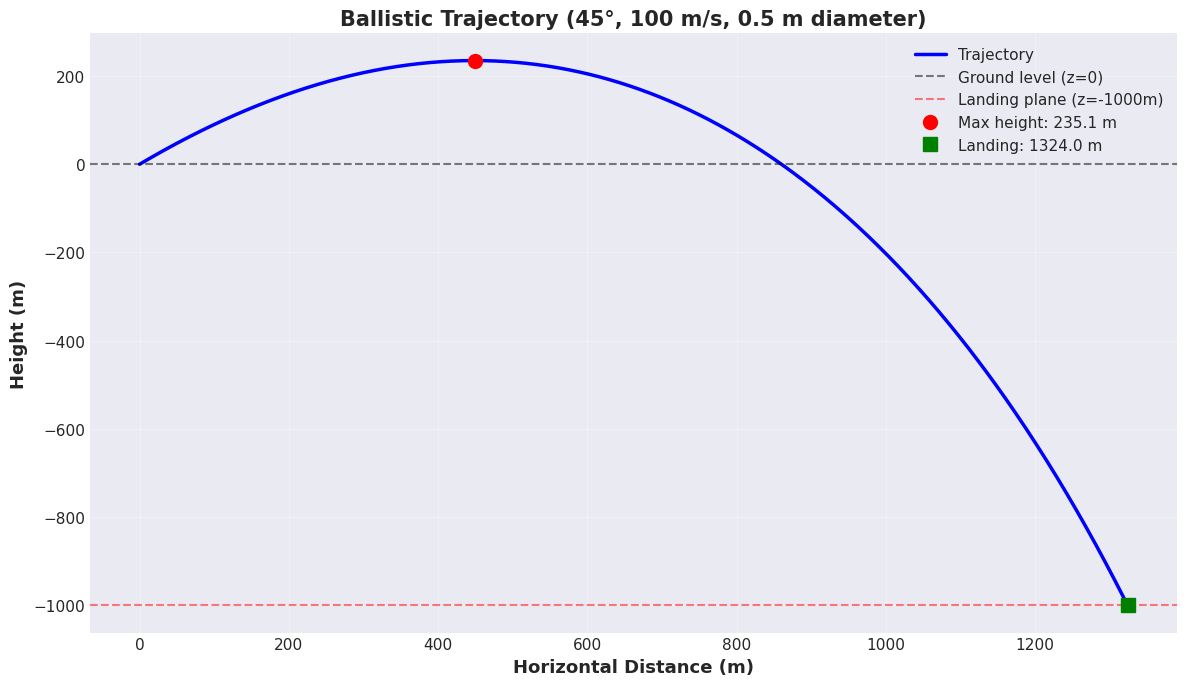


✓ Single trajectory plot complete!


In [3]:
# Plot the trajectory
plt.figure(figsize=(12, 7))
plt.plot(x_coords, z_coords, 'b-', linewidth=2.5, label='Trajectory')
plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Ballistic Trajectory (45°, 100 m/s, 0.5 m diameter)', fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level (z=0)')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane (z=-1000m)')

# Mark maximum height
max_height_idx = np.argmax(z_coords)
plt.plot(x_coords[max_height_idx], z_coords[max_height_idx], 'ro', markersize=10, 
         label=f'Max height: {np.max(z_coords):.1f} m')

# Mark landing point
plt.plot(x_coords[-1], z_coords[-1], 'gs', markersize=10, 
         label=f'Landing: {x_coords[-1]:.1f} m')

plt.legend(fontsize=11, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Single trajectory plot complete!")

> **CHECK:** you should see a smooth curve (the trajectory), a red dot at the highest point,
> and a green square where the block lands.
>
> **TIP:** this landing distance is measured on **flat ground** (a flat line at z = −1000 m).
> Real volcanoes are not flat, so this number is **too large**. Notebook 2 makes it realistic.

### Experiment 1: Does the angle change the distance?


In [4]:
# Define angles to test
angles = [30, 45, 60]
vi = 100.0
diam = 0.5

# Store results
trajectories = {}
max_distances = {}
max_heights = {}

print("Calculating trajectories for different angles...\n")

for angle in angles:
    print(f"Processing {angle}°...")
    traj = eject(angle, vi, diam)
    trajectories[angle] = traj
    max_distances[angle] = traj[-1, 0]
    max_heights[angle] = np.max(traj[:, 1])
    print(f"  Max distance: {max_distances[angle]:.2f} m")
    print(f"  Max height: {max_heights[angle]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different angles...

Processing 30°...
  Max distance: 1435.89 m
  Max height: 120.52 m

Processing 45°...
  Max distance: 1323.95 m
  Max height: 235.10 m

Processing 60°...
  Max distance: 1037.27 m
  Max height: 347.97 m

✓ All trajectories calculated!


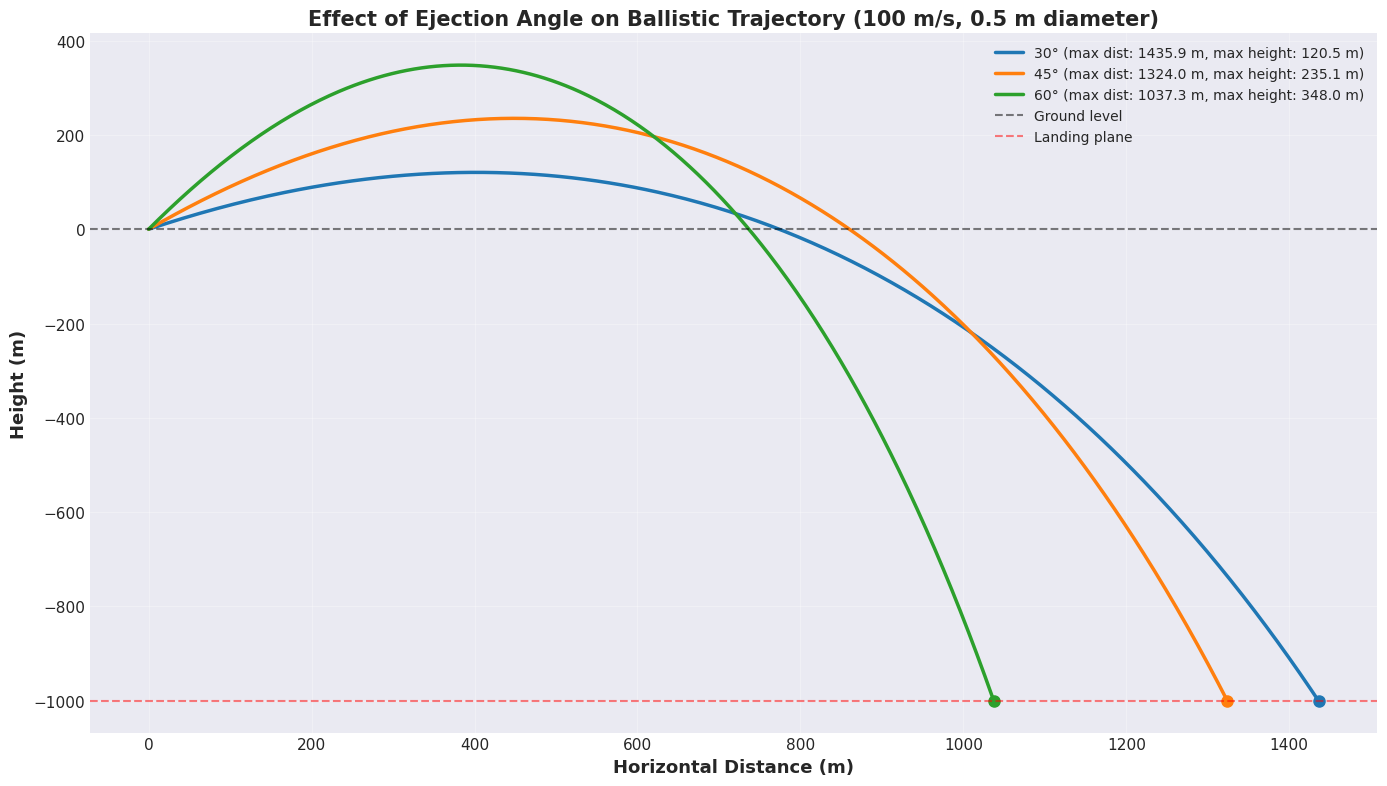


✓ Angle comparison plot complete!


In [5]:
# Plot comparison
plt.figure(figsize=(14, 8))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, orange, green

for idx, angle in enumerate(angles):
    traj = trajectories[angle]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=colors[idx],
             label=f'{angle}° (max dist: {max_distances[angle]:.1f} m, max height: {max_heights[angle]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Ejection Angle on Ballistic Trajectory (100 m/s, 0.5 m diameter)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Angle comparison plot complete!")

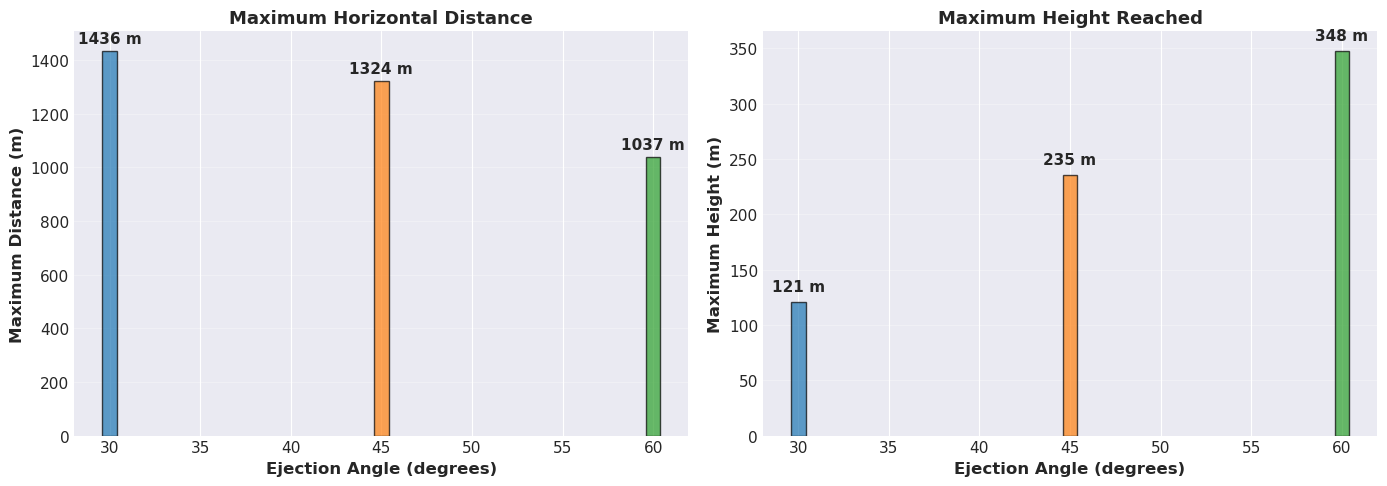


✓ Summary bar charts complete!


In [6]:
# Create a summary bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances
ax1.bar(angles, [max_distances[a] for a in angles], color=colors, alpha=0.7, edgecolor='black')
ax1.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Maximum Horizontal Distance', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')
for i, angle in enumerate(angles):
    ax1.text(angle, max_distances[angle] + 30, f'{max_distances[angle]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights
ax2.bar(angles, [max_heights[a] for a in angles], color=colors, alpha=0.7, edgecolor='black')
ax2.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Maximum Height Reached', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
for i, angle in enumerate(angles):
    ax2.text(angle, max_heights[angle] + 10, f'{max_heights[angle]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Summary bar charts complete!")

**What you should notice:** with air drag, the **farthest** distance comes from an angle a
little **below** 45°. Steeper angles fly higher but land closer.

### Experiment 2: Does the speed change the distance?


In [7]:
# Define velocities to test
velocities = [50, 75, 100, 125]
angle = 45.0
diam = 0.5

# Store results
vel_trajectories = {}
vel_max_distances = {}
vel_max_heights = {}

print("Calculating trajectories for different initial velocities...\n")

for vel in velocities:
    print(f"Processing {vel} m/s...")
    traj = eject(angle, vel, diam)
    vel_trajectories[vel] = traj
    vel_max_distances[vel] = traj[-1, 0]
    vel_max_heights[vel] = np.max(traj[:, 1])
    print(f"  Max distance: {vel_max_distances[vel]:.2f} m")
    print(f"  Max height: {vel_max_heights[vel]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different initial velocities...

Processing 50 m/s...
  Max distance: 596.53 m
  Max height: 63.32 m

Processing 75 m/s...
  Max distance: 952.98 m
  Max height: 138.41 m

Processing 100 m/s...
  Max distance: 1323.95 m
  Max height: 235.10 m

Processing 125 m/s...
  Max distance: 1694.11 m
  Max height: 347.19 m

✓ All trajectories calculated!


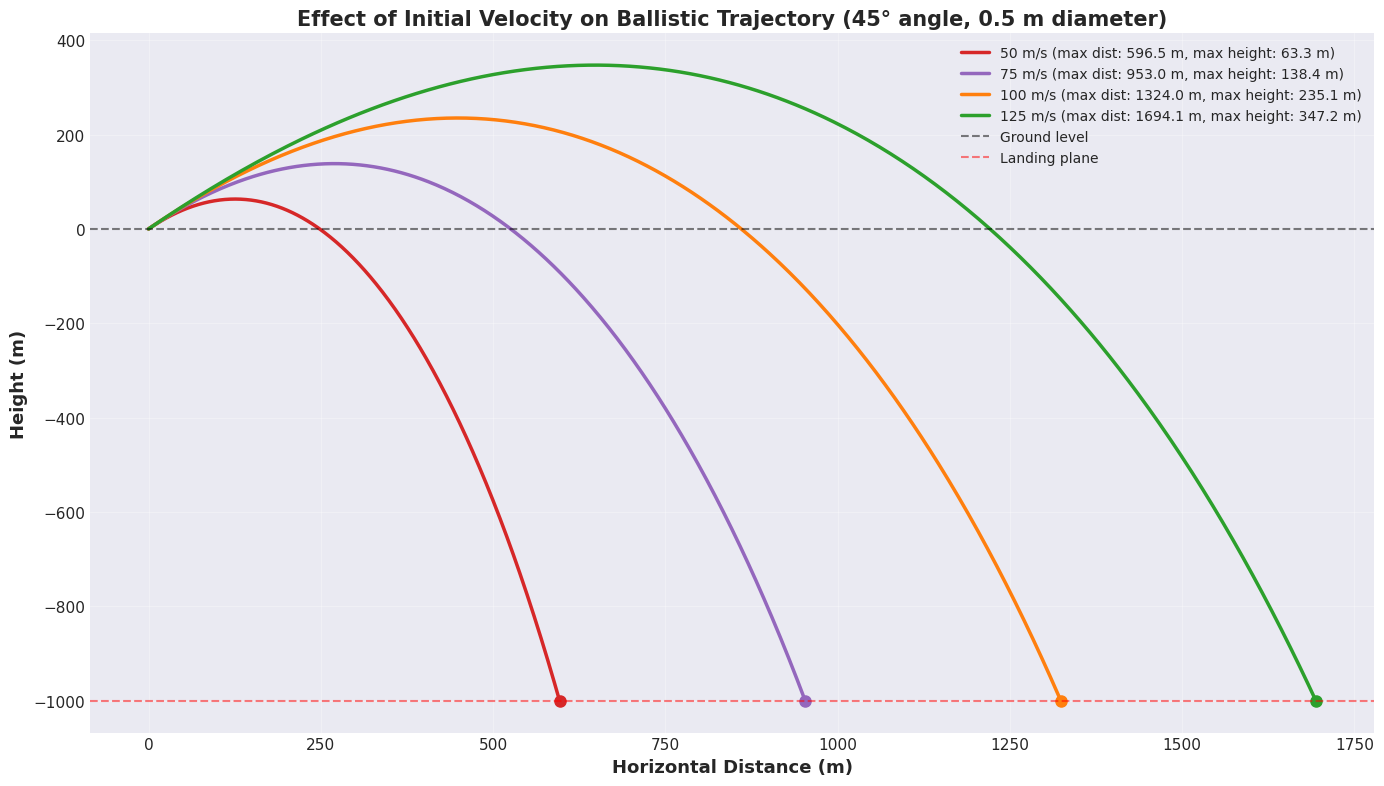


✓ Velocity comparison plot complete!


In [8]:
# Plot comparison
plt.figure(figsize=(14, 8))

vel_colors = ['#d62728', '#9467bd', '#ff7f0e', '#2ca02c']  # Red, purple, orange, green

for idx, vel in enumerate(velocities):
    traj = vel_trajectories[vel]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=vel_colors[idx],
             label=f'{vel} m/s (max dist: {vel_max_distances[vel]:.1f} m, max height: {vel_max_heights[vel]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=vel_colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Initial Velocity on Ballistic Trajectory (45° angle, 0.5 m diameter)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Velocity comparison plot complete!")

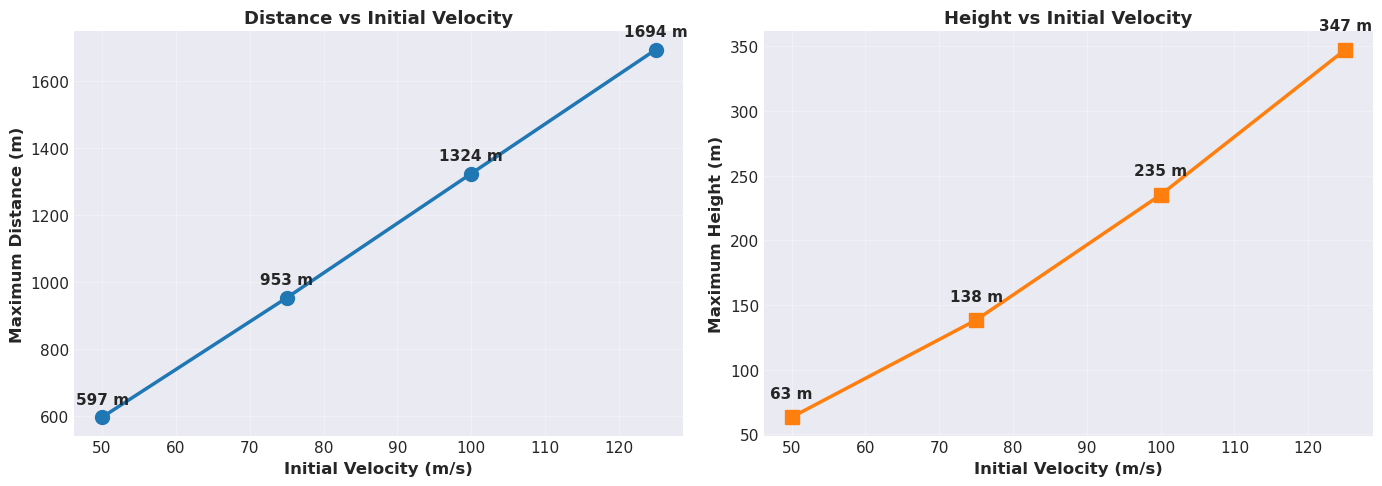


✓ Velocity scaling plots complete!


In [9]:
# Create a summary visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances vs velocity
ax1.plot(velocities, [vel_max_distances[v] for v in velocities], 'o-', 
         linewidth=2.5, markersize=10, color='#1f77b4')
ax1.set_xlabel('Initial Velocity (m/s)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Distance vs Initial Velocity', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
for vel in velocities:
    ax1.text(vel, vel_max_distances[vel] + 40, f'{vel_max_distances[vel]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights vs velocity
ax2.plot(velocities, [vel_max_heights[v] for v in velocities], 's-', 
         linewidth=2.5, markersize=10, color='#ff7f0e')
ax2.set_xlabel('Initial Velocity (m/s)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Height vs Initial Velocity', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
for vel in velocities:
    ax2.text(vel, vel_max_heights[vel] + 15, f'{vel_max_heights[vel]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Velocity scaling plots complete!")

**What you should notice:** speed has the biggest effect. About **two times the speed gives
about four times the distance**.

### Experiment 3: Does the block size change the distance?


In [10]:
# Define diameters to test (in meters)
diameters = [0.2, 0.5, 1.0, 2.0]  # 20 cm, 50 cm, 1 m, 2 m
angle = 45.0
vel = 100.0

# Store results
size_trajectories = {}
size_max_distances = {}
size_max_heights = {}

print("Calculating trajectories for different projectile sizes...\n")

for d in diameters:
    print(f"Processing diameter {d} m ({d*100:.0f} cm)...")
    traj = eject(angle, vel, d)
    size_trajectories[d] = traj
    size_max_distances[d] = traj[-1, 0]
    size_max_heights[d] = np.max(traj[:, 1])
    print(f"  Max distance: {size_max_distances[d]:.2f} m")
    print(f"  Max height: {size_max_heights[d]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different projectile sizes...

Processing diameter 0.2 m (20 cm)...
  Max distance: 1038.64 m
  Max height: 213.32 m

Processing diameter 0.5 m (50 cm)...
  Max distance: 1323.95 m
  Max height: 235.10 m

Processing diameter 1.0 m (100 cm)...
  Max distance: 1463.31 m
  Max height: 244.34 m

Processing diameter 2.0 m (200 cm)...
  Max distance: 1546.48 m
  Max height: 249.46 m

✓ All trajectories calculated!


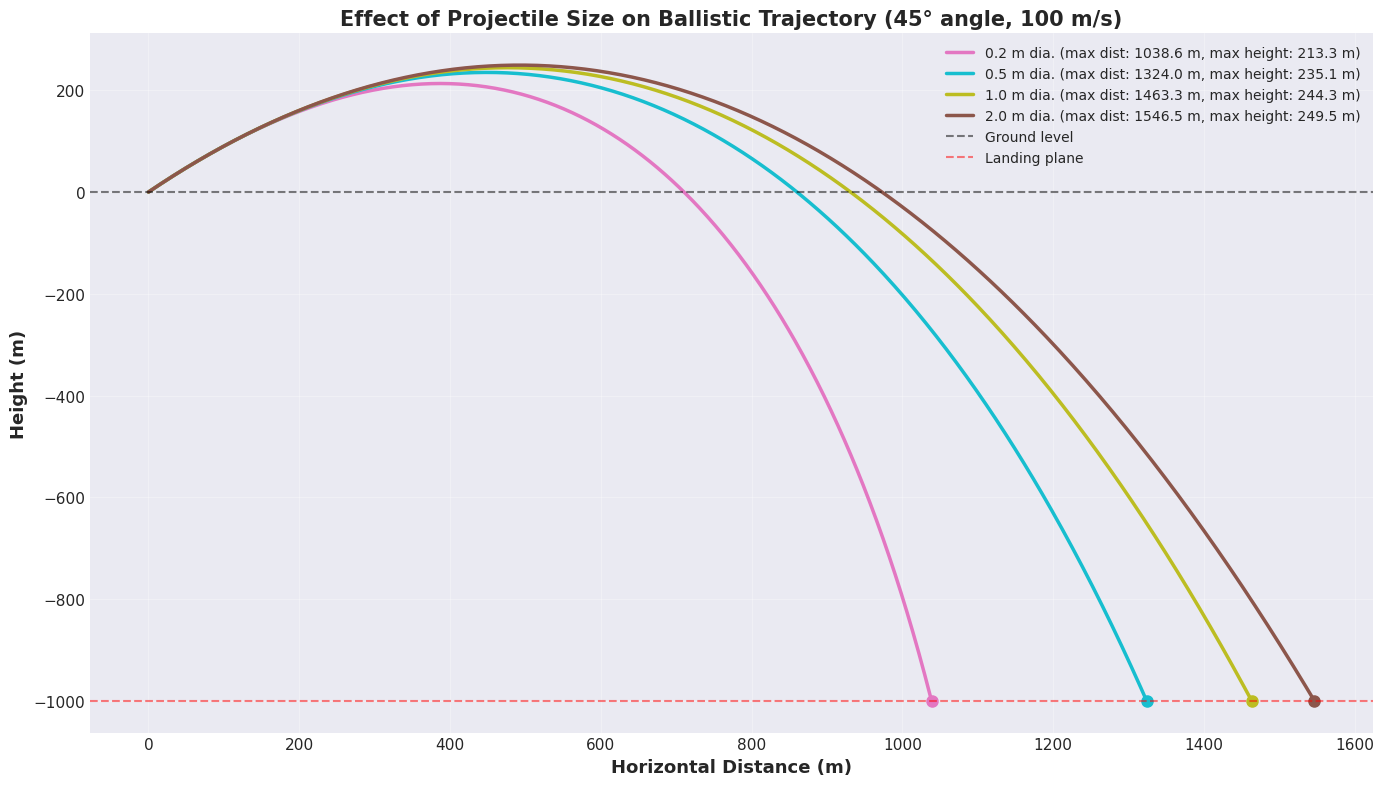


✓ Size comparison plot complete!


In [11]:
# Plot comparison
plt.figure(figsize=(14, 8))

size_colors = ['#e377c2', '#17becf', '#bcbd22', '#8c564b']  # Pink, cyan, yellow-green, brown

for idx, d in enumerate(diameters):
    traj = size_trajectories[d]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=size_colors[idx],
             label=f'{d} m dia. (max dist: {size_max_distances[d]:.1f} m, max height: {size_max_heights[d]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=size_colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Projectile Size on Ballistic Trajectory (45° angle, 100 m/s)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Size comparison plot complete!")

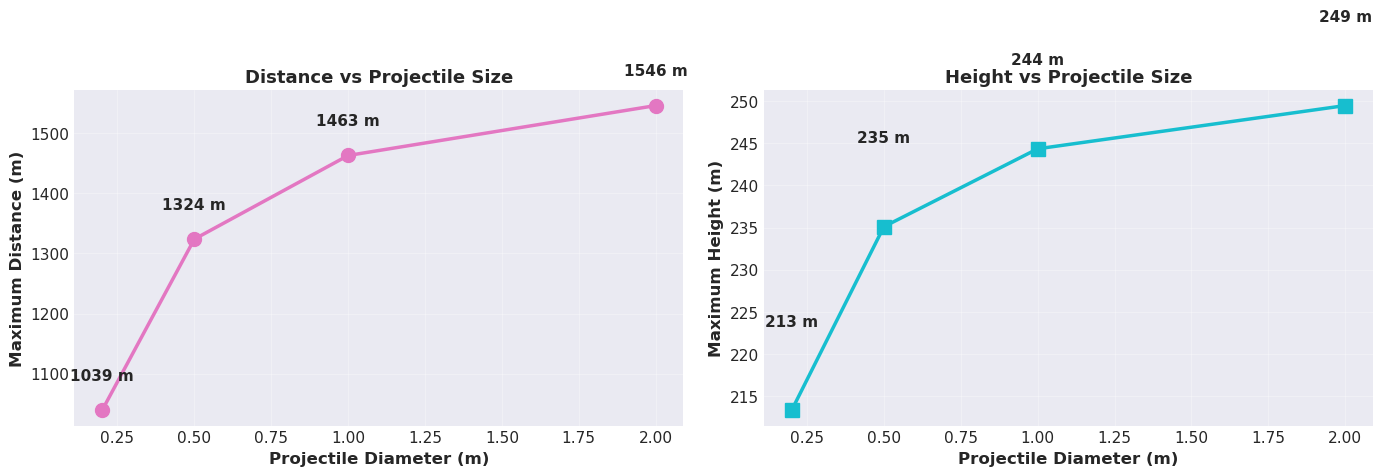


✓ Size scaling plots complete!


In [12]:
# Create comparison charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances vs size
ax1.plot(diameters, [size_max_distances[d] for d in diameters], 'o-', 
         linewidth=2.5, markersize=10, color='#e377c2')
ax1.set_xlabel('Projectile Diameter (m)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Distance vs Projectile Size', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
for d in diameters:
    ax1.text(d, size_max_distances[d] + 50, f'{size_max_distances[d]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights vs size
ax2.plot(diameters, [size_max_heights[d] for d in diameters], 's-', 
         linewidth=2.5, markersize=10, color='#17becf')
ax2.set_xlabel('Projectile Diameter (m)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Height vs Projectile Size', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
for d in diameters:
    ax2.text(d, size_max_heights[d] + 10, f'{size_max_heights[d]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Size scaling plots complete!")

**What you should notice:** bigger blocks travel **farther**. They have more mass, so the air
slows them less.

### Experiment 4: Explore it yourself (optional)

If the widget library is installed, the slider below lets you change all three inputs at once.


In [13]:
# Try to import ipywidgets for interactive plots
try:
    from ipywidgets import interact, FloatSlider, IntSlider
    WIDGETS_AVAILABLE = True
    print("✓ ipywidgets available - interactive plot enabled!")
except ImportError:
    WIDGETS_AVAILABLE = False
    print("⚠ ipywidgets not available. Install with: pip install ipywidgets")
    print("Skipping interactive example.")

✓ ipywidgets available - interactive plot enabled!


In [14]:
if WIDGETS_AVAILABLE:
    def plot_interactive_trajectory(angle=45, velocity=100, diameter=0.5):
        """
        Interactive trajectory plotting function.
        """
        # Calculate trajectory
        traj = eject(angle, velocity, diameter)
        x_coords = traj[:, 0]
        z_coords = traj[:, 1]
        
        # Create plot
        plt.figure(figsize=(12, 7))
        plt.plot(x_coords, z_coords, 'b-', linewidth=2.5, label='Trajectory')
        plt.xlabel('Horizontal Distance (m)', fontsize=12, fontweight='bold')
        plt.ylabel('Height (m)', fontsize=12, fontweight='bold')
        plt.title(f'Interactive Ballistic Trajectory\n' + 
                  f'Angle: {angle}°, Velocity: {velocity} m/s, Diameter: {diameter} m',
                  fontsize=13, fontweight='bold')
        plt.grid(True, alpha=0.3)
        plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5)
        plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5)
        
        # Mark key points
        max_height_idx = np.argmax(z_coords)
        plt.plot(x_coords[max_height_idx], z_coords[max_height_idx], 'ro', 
                 markersize=8, label=f'Max height: {np.max(z_coords):.1f} m')
        plt.plot(x_coords[-1], z_coords[-1], 'gs', markersize=8, 
                 label=f'Landing: {x_coords[-1]:.1f} m')
        
        plt.legend(fontsize=10)
        plt.tight_layout()
        plt.show()
    
    # Create interactive widget
    interact(plot_interactive_trajectory,
             angle=IntSlider(min=15, max=75, step=5, value=45, 
                            description='Angle (°):'),
             velocity=IntSlider(min=25, max=500, step=5, value=100, 
                               description='Velocity (m/s):'),
             diameter=FloatSlider(min=0.1, max=3.0, step=0.1, value=0.5, 
                                 description='Diameter (m):'))
else:
    print("Interactive plot not available. Install ipywidgets to enable.")

interactive(children=(IntSlider(value=45, description='Angle (°):', max=75, min=15, step=5), IntSlider(value=1…


## Part 2: Record your scenario

**Your turn!!:** in the cell below, change the three numbers marked `<-- change this`, then run it. Write down the **flat-ground landing distance** in the classwork document. You can use it for a first, rough hazard circle.


In [15]:
# ===== CHANGE THESE THREE NUMBERS TO YOUR OWN SCENARIO =====
my_angle    = 45.0    # degrees   <-- change this
my_velocity = 100.0   # m/s       <-- change this
my_diameter = 0.5     # m         <-- change this
# ===========================================================

traj = eject(my_angle, my_velocity, my_diameter)
x, z = traj[:, 0], traj[:, 1]
max_height = z.max()
landing_distance = x[-1]

print(f"Scenario: {my_angle}°, {my_velocity} m/s, {my_diameter} m block\n")
print(f"Maximum height          = {max_height:.0f} m")
print(f"Flat-ground landing     = {landing_distance:.0f} m")
print("\nNote: flat ground gives a large, safe over-estimate. Notebook 2 makes it realistic.")

Scenario: 45.0°, 100.0 m/s, 0.5 m block

Maximum height          = 235 m
Flat-ground landing     = 1324 m

Note: flat ground gives a large, safe over-estimate. Notebook 2 makes it realistic.



## Part 3 (optional): A first hazard circle in QGIS

You can already make a simple, rough hazard zone from this one distance.

> This distance is measured on **flat ground**, so the circle is **too large** (a safe
> over-estimate). Notebook 2 makes the zone realistic and direction-by-direction.

1. Open **QGIS** and start a **New Project**.
2. Add the vent point: **Layer --> Add Layer --> Add Delimited Text Layer** (a CSV with one row:
   `lon,lat`). Set **X = lon**, **Y = lat**, **CRS = EPSG:4326**.
3. Set a **metric CRS**: click the CRS code at the bottom-right of QGIS and choose the correct
   **UTM zone** for your volcano (units = meters).
4. Open **Vector --> Geoprocessing Tools --> Buffer**. Set **Input** = the vent point, and
   **Distance** = your flat-ground landing distance.
5. Click **Run**, then style the circle red and about **40% transparent**.

> **Why the CRS matters:** in a degrees CRS, a distance of "1221" means 1221 *degrees* and that is wrong!
> In a UTM (meters) CRS, "1221" correctly means 1221 meters.



## What is next

Open **Notebook 2: EJECT! with topography** to use the real shape of the volcano, find impact
distances in four directions, and build the full hazard map in QGIS.

> **Looking ahead:** one scenario gives a single estimate. Real hazard work runs **many**
> eruptions and reports the chances, which produces a **probabilistic** map. We do not run a probabilistic study.


## If something goes wrong

| Problem | Try this |
|---------|----------|
| `ModuleNotFoundError: No module named 'eject'` | The model files must end in **.py**, not **.pyw**. Rename `eject.pyw` to `eject.py` (and the other model files), then run the Setup cell again. |
| `eject is not defined` | Run the **Setup** cell first, then run the other cells in order. |
| A plot is empty | Run every cell from the top. A later cell needs the results of an earlier one. |
| The slider does not appear | Install the widget library: `pip install ipywidgets`. This step is optional. |
